# Week:3 Data pre-processing 

### Objective:
The objective of this assignment is to perform exploratory data analysis, data pre-processing, data cleaning, scaling, transformation, check correlation between variables and perform sampling.

We use the Fatal Police Shooting data to answer the questions given in this notebook.

### Fatal Police Shooting Data

**About dataset**\
The dataset consists of following columns
1. **id**                         : unqiue identifier of each victim
2. **name**                       : name of a victim
3. **date**                       : date on fatal shooting 
4. **manner_of_death**            : manner of death classification
    * Shot
    * Shot and Tasered
5. **armed**                      : indicates that the victim was armed with some sort of implement that a police officer believed could inflict harm
    * undetermined: it is not known whether or not the victim had a weapon
    * unknown: the victim was armed, but it is not known what the object was
    * unarmed: the victim was not armed
6. **age**                        : age of victim
7. **gender**                     : the gender of the victim. The Post identifies victims by the gender they identify with if reports indicate that it differs from their biological sex.
    * M: Male
    * F: Female
    * None: Unknown
8. **race**                       : race of victim
    * W: White, non-Hispanic
    * B: Black, non-Hispanic
    * A: Asian
    * N: Native American
    * H: Hispanic
    * O: Other
    * None: unknown
9. **city**                       : the municipality where the fatal shooting took place. Note that in some cases this field may contain a county name if a more specific municipality is unavailable or unknown.
10. **state**                     : two-letter postal code abbreviation
11. **signs_of_mental_illness**   : News reports have indicated the victim had a history of mental health issues, expressed suicidal intentions or was experiencing mental distress at the time of the shooting.
12. **threat_level**              : These would include incidents where officers or others were shot at, threatened with a gun, attacked with other weapons or physical force, etc. The attack category is meant to flag the highest level of threat. The other and undetermined categories represent all remaining cases. Other includes many incidents where officers or others faced significant threats. 
13. **flee**                      : News reports have indicated the victim was moving away from officers
    * Foot
    * Car
    * Not fleeing
14. **body_camera**               : News reports have indicated an officer was wearing a body camera and it may have recorded some portion of the incident.

## Let's Begin

In [74]:
# Install the libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [75]:
# Load the dataframe 
df = pd.read_csv('week_2_assignment_output.csv')
df.head()

# TODO: Code to fill: 
# 1. '<<__A__>>' --> Path of the csv file

,Unnamed: 0,id,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,count,age_categories,year
0,0,3,Tim Elliot,2015-01-02,shot,gun,53.0,M,A,Shelton,WA,True,attack,Not fleeing,False,1,Senior citizens,2015
1,1,4,Lewis Lee Lembke,2015-01-02,shot,gun,47.0,M,W,Aloha,OR,False,attack,Not fleeing,False,2,Adult,2015
2,2,5,John Paul Quintero,2015-01-03,shot and Tasered,unarmed,23.0,M,H,Wichita,KS,False,other,Not fleeing,False,9,Youth,2015
3,3,8,Matthew Hoffman,2015-01-04,shot,toy weapon,32.0,M,W,San Francisco,CA,True,attack,Not fleeing,False,15,Youth,2015
4,4,9,Michael Rodriguez,2015-01-04,shot,nail gun,39.0,M,H,Evans,CO,False,attack,Not fleeing,False,2,Adult,2015


In [76]:
# Check the shape of the dataset
df.shape

(4478, 18)

### Question: 1 ( 1 Mark )

Check and Handle the missing values (NaN) present in each column with the respective methods 

In [77]:
# Check the dataframe for missing values in the column before handling
df.columns[df.isnull().any()].tolist()

# TODO: Code to fill: 

# 1. '<<__A__>>' --> Use correct method
# 2. '<<__B__>>' --> Use correct method


['armed', 'age', 'gender', 'race', 'flee', 'age_categories']

In [78]:
# Handle the missing values 
df['armed'].fillna(df['armed'].mode()[0], inplace=True)
df['age'].fillna(df['age'].median(), inplace=True)
df['gender'].fillna(df['gender'].mode()[0], inplace=True)
df['race'].fillna(df['race'].mode()[0], inplace=True)
df['flee'].fillna(df['flee'].mode()[0], inplace=True)
# using the same logic to recompute age categories
col = 'age'
ranges = [(df[col] > 50) & (df[col] <= 120), (df[col] > 34) & (df[col] <= 50), (df[col] > 21) & (df[col] <= 34), (df[col] > 12) & (df[col] <= 21), (df[col] >= 0) & (df[col] <= 12)]
cats = ['Senior citizens', 'Adult', 'Youth', 'Teenage', 'Child']
age_cat = np.select(ranges, cats, default=np.nan)
df['age_categories'] =  age_cat

# write your code here to handle missing values for other columns

# TODO: Code to fill: 

# 1. '<<__A__>>' --> Appropriate filling method
# 2. '<<__B__>>' --> column_name
# 3. '<<__C__>>' --> column_name

In [79]:
# Check dataframe after handling missing values 
df.columns[df.isnull().any()].tolist()

# TODO: Code to fill: 

# 1. '<<__A__>>' --> Use correct method
# 2. '<<__B__>>' --> Use correct method

[]

### Question: 2 (1 Mark )
Handle the outliers present in the age column 

<Axes: >

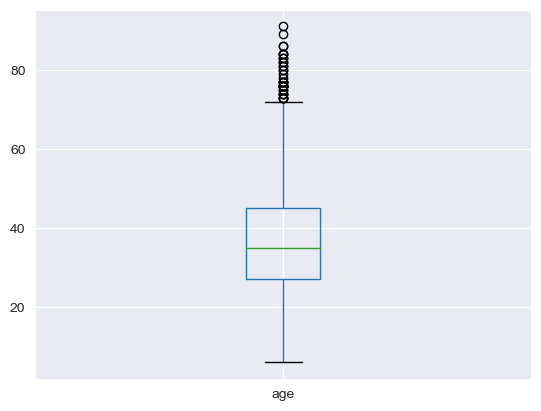

In [80]:
# Display the box plot before handling outliers in the age column
df.boxplot('age')
# TODO: Code to fill: 

# 1. '<<__A__>>' --> Display the box plot before handling outliers in the age column

Observations
All the outliers are on the upper end, aged above 72.
The distribution is right-skewed as seen in the box plot.

In [81]:
# Quantile 1 of age column (25 percentage)
Q1 = df['age'].quantile(0.25)
# Quantile 3 of age column (75 percentage)
Q3 = df['age'].quantile(0.75)

In [82]:
# Inter Quartile Range
IQR = Q3 - Q1
IQR

18.0

In [83]:
# Outliers present in upper case
upper_case = Q3 + (1.5*IQR)
print(upper_case)
# Outliers present in lower case
lower_case = Q1 - (1.5*IQR)
print(lower_case)

72.0
0.0


In [84]:
outliers = df.loc[(df['age'] > upper_case) | (df['age'] < lower_case)]['age']
print(outliers)

29      75.0
92      74.0
127     77.0
275     83.0
315     76.0
426     86.0
518     76.0
598     77.0
664     76.0
1220    76.0
1434    80.0
1634    82.0
1678    86.0
1801    76.0
1880    83.0
1907    73.0
2162    91.0
2216    73.0
2270    79.0
2347    74.0
2384    75.0
2392    82.0
2646    76.0
3067    78.0
3075    84.0
3148    84.0
3252    81.0
3314    89.0
3345    73.0
3385    77.0
3731    76.0
3741    84.0
3950    81.0
4035    80.0
4151    77.0
4261    76.0
4368    74.0
4388    76.0
4436    73.0
Name: age, dtype: float64


In [85]:
# Remove the outliers in age column
df = df.loc[~((df['age'] > upper_case) | (df['age'] < lower_case))]

# TODO: Code to fill: 

# 1. '<<__B__>>' --> write the your command to remove outliers outside upper case and lower case

<Axes: >

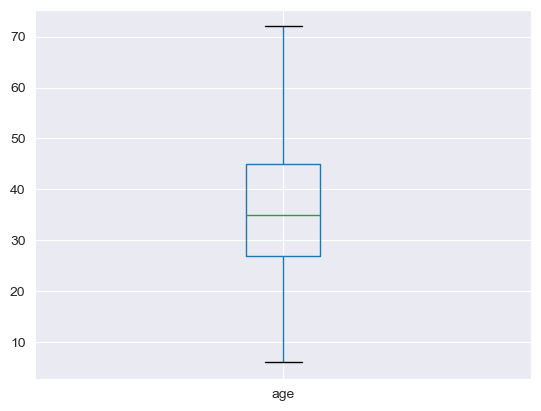

In [86]:
# Display the box plot after handling outliers in the age column
df.boxplot('age')
# TODO: Code to fill: 

# 1  '<<__C__>>' --> Display the box plot after handling outliers in the age column

There are no outliers now.

### Question: 3 ( 1 Mark )
Plot a bar graph which tells most repeated weapons used to attack the people  

/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


Text(0.5, 1.0, 'Frequencies of arms')

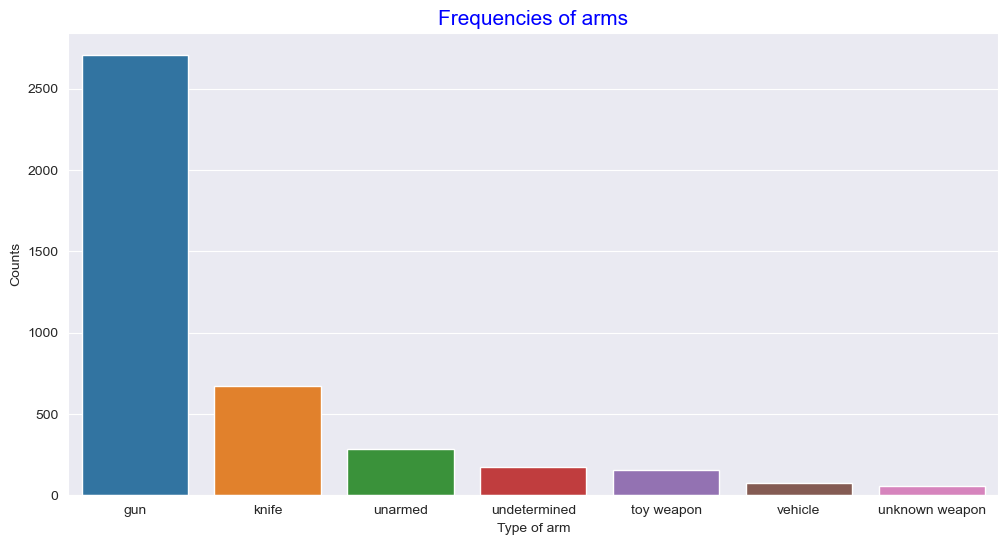

In [87]:
# Get the value count of armed column
armed = df.armed.value_counts()
# set the plot size
plt.figure(figsize=(12, 6))
# Create a bar plot using above variable by filtering upto 7 rows 
sns.barplot(x=armed[:7].index,y=armed[:7].values)
plt.ylabel('Counts')
plt.xlabel('Type of arm')
plt.title('Frequencies of arms', fontsize=15, color='blue')

# TODO: Code to fill: 

# 1. '<<__A__>>' --> Set the plot size
# 2. '<<__B__>>' --> set a name for y label
# 3. '<<__C__>>' --> set a name for x label
# 4. '<<__D__>>' --> set a title for the graph with a  fontsize 15 in the colour of blue

Guns have been implicated the most in these incidents.

### Question: 4 ( 2 Marks )
Generate a bar plot to identify days in which the count of attacks are reported most 

In [88]:
import datetime
# Create a new columns day, month, year using date column with the help of pandas to_datetime method
df['day'] = pd.to_datetime(df['date']).dt.day
df['month'] = pd.to_datetime(df['date']).dt.month
df['year'] = pd.to_datetime(df['date']).dt.year
df['dow'] = pd.to_datetime(df['date']).apply(datetime.date.weekday)
days = ['0 Sunday', '1  Monday', '2 Tuesday', '3 Wednesday', '4 Thursday', '5 Friday', '6 Saturday']
cond = [df['dow'] == 0, df['dow'] == 1, df['dow'] == 2, df['dow'] == 3, df['dow'] == 4, df['dow'] == 5, df['dow'] == 6]
df['dow'] = np.select(cond, days)

/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf 

Text(0.5, 0, 'Day of week')

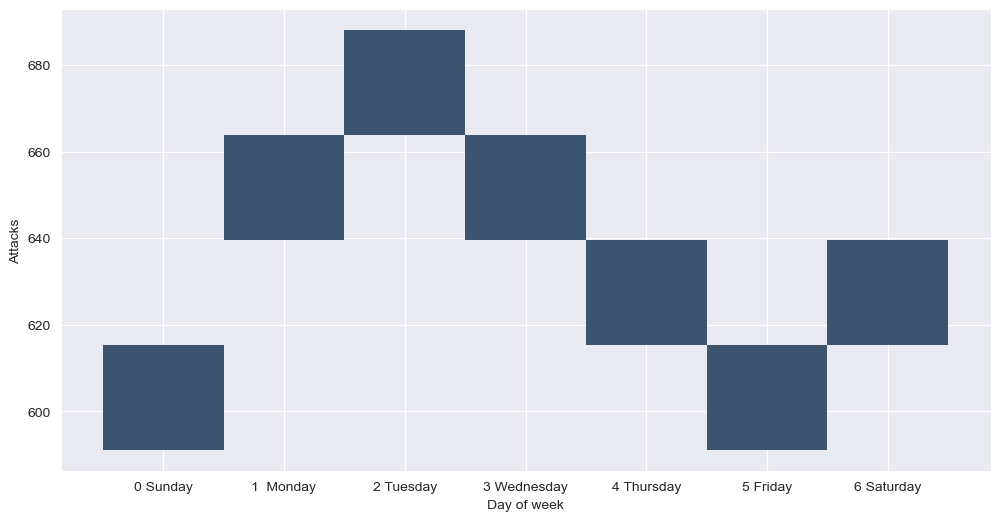

In [89]:
#Plot a bar graph in which days the count of attcks are more
counts = df.groupby(['dow'])[['id']].count()
plt.figure(figsize=(12, 6))
sns.histplot(data=counts, x="dow", y="id")
plt.ylabel('Attacks')
plt.xlabel('Day of week')
# TODO: Code to fill: 

# 1. '<<__A__>>' --> Fill the column name for which you want to plot a bar graph
# 2. '<<__B__>>' --> write your method here to count the values
# 3. '<<__C__>>' --> fill the type of plot
# 4. '<<__D__>>' --> Set plot size (12,6)

Attacks peak on Tuesdays with most attacks happening mid-week.
Friday through Sunday see fewer attacks.

### Question: 5 ( 2 Marks )
Display the Top 10 states where the high number of cases recorded 

/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/slakshmanan/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


Text(0.5, 1.0, 'Top 10 states')

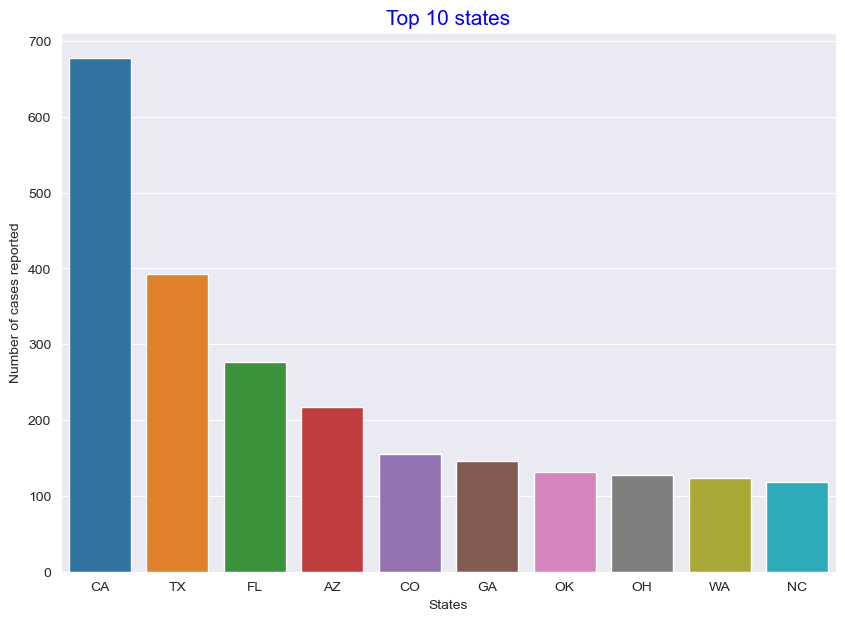

In [90]:
# Write your code here
state = df.groupby('state', as_index=False)[['id']].count().nlargest(10, columns='id')
# Display the Top 10 states using bar chart
plt.figure(figsize=(10,7))
sns.barplot(data=state, x="state", y="id")
plt.ylabel("Number of cases reported")
plt.xlabel('States')
plt.title('Top 10 states',color = 'blue',fontsize=15)


# TODO: Code to fill: 

# 1. '<<__A__>>' --> Fill the column name 
# 2. '<<__B__>>' --> write your method here to count the values
# 3. '<<__C__>>' --> Provide x axis values from state dataframe created in previous step
# 4. '<<__D__>>' --> Provide y axis values from state dataframe created in previous step


California is the top state in attacks and sees almost double that of Texas which is the next leading state.

### Question: 6 ( 1 Mark )
Drop the features that have more unique string values and not relevant to the model.

In [91]:
# Drop the features that have more unique string values and not relevant to the model.
high_cardinality_cols = [col for col in df.columns if df[col].nunique() > 1000]
print(high_cardinality_cols)
# id, name, date and city have high unique counts, but city is important for any location analysis
df.drop(columns=['id', 'name', 'date'],axis=1,inplace=True)



['Unnamed: 0', 'id', 'name', 'date', 'city']


In [92]:
#Display the top 5 rows of dataset after droping the unnecessary features
df.head(5)

# TODO: Code to fill: 

# 1. '<<__A__>>' --> Fill appropriate method for removing features
# 2. '<<__B__>>' --> column names 
# 3. '<<__C__>>' --> Give the axis for removing features
# 3. '<<__D__>>' --> Use the correct method to get top 5 rows of dataset after droping the unnessacary features

,Unnamed: 0,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera,count,age_categories,year,day,month,dow
0,0,shot,gun,53.0,M,A,Shelton,WA,True,attack,Not fleeing,False,1,Senior citizens,2015,2,1,4 Thursday
1,1,shot,gun,47.0,M,W,Aloha,OR,False,attack,Not fleeing,False,2,Adult,2015,2,1,4 Thursday
2,2,shot and Tasered,unarmed,23.0,M,H,Wichita,KS,False,other,Not fleeing,False,9,Youth,2015,3,1,5 Friday
3,3,shot,toy weapon,32.0,M,W,San Francisco,CA,True,attack,Not fleeing,False,15,Youth,2015,4,1,6 Saturday
4,4,shot,nail gun,39.0,M,H,Evans,CO,False,attack,Not fleeing,False,2,Adult,2015,4,1,6 Saturday


### Question: 7 ( 2 Marks )
Create a line plot that shows the number of attacks every year according to race

<Axes: xlabel='year'>

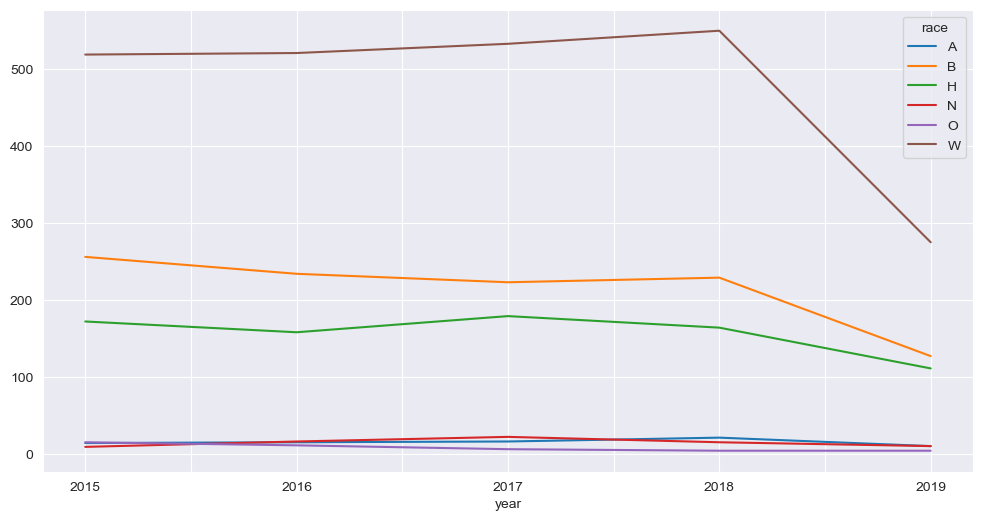

In [93]:
# Write your code here
pd.crosstab(df['year'].astype('category'),df['race']).plot.line(figsize=(12,6))


# TODO: Code to fill: 

# 1. '<<__A__>>' --> Fill the exact column name
# 2. '<<__B__>>' --> Fill the exact column name

## Thank you!